# 3. The model, and the honest test

**Life Expectancy Predictor · notebook 3 of 7**

With clean data, we can train a model and ask how good it is. This notebook does both, and shows why the project reports *two* headline scores (R² 0.96 and R² 0.90) rather than one. The second number is the honest one, and the gap between them is one of the project's main findings.

The model is trained live here, with the project's own code, so the numbers below are reproduced rather than copied.

## Step 1: What kind of model, and why

**What we are looking for.** A method that can learn "countries with high adult mortality and low schooling tend to have short life expectancy" from 2,928 examples, without being told the rules in advance.

The project uses a **random forest**: 200 decision trees, each grown on a different random sample of the data, whose predictions are averaged. One decision tree is a flowchart of yes/no questions ("Is adult mortality above 300? Is schooling below 8 years?") ending in a predicted number. A single tree is easy to fool; 200 trees that disagree a little and get averaged are robust and accurate on tabular data like this, and need very little tuning (notebook 7 confirms that).

In [1]:
# Setup: find the project folder and load the project's own code and settings.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config_loader import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config = load_config(str(ROOT / "config" / "who_life_expectancy.yaml"), base_dir=str(ROOT))

def results(name):
    """Load one of the saved results files in model/."""
    return json.loads((ROOT / "model" / f"{name}.json").read_text(encoding="utf-8"))

print("Project folder:", ROOT.name)
from data_prep import get_unclipped_df
from train_model import rf_pipeline
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error

df = get_unclipped_df(config)
X = df[config.predictor_columns].to_numpy()
y = df[config.target_column].to_numpy()
groups = df["Country"].to_numpy()
mp = config.model_params
model = rf_pipeline(config, n_estimators=mp["n_estimators"], random_state=mp["random_state"], n_jobs=-1)
print("The model, step by step:")
for name, step in model.steps:
    print(f"  {name}: {type(step).__name__}")
print(f"\nRows: {len(df):,}   Inputs: {len(config.predictor_columns)}   Trees: {mp['n_estimators']}")

Project folder: nb


The model, step by step:
  clip: FoldWinsorizer
  rf: RandomForestRegressor

Rows: 2,928   Inputs: 13   Trees: 200


**How to read it.** The model has two parts that always run together: `clip` (the leak-free outlier clipping from notebook 2) and `rf` (the random forest).

**What it means.** Because clipping is inside the model, every test below is automatically leak-free: whatever rows the model is trained on are the only rows the clipping ever learns from.

**What's next and why.** First, the standard way to test a model, which gives the flattering score.

## Step 2: The standard test: hold back a random 20% of rows

**What we are looking for.** Train on 80% of the rows, predict the other 20%, and compare predictions with the truth. This is how the original project measured itself, and it is how most introductory courses teach it.

Two scores are used throughout the project:

- **R² (R-squared)**: the share of the variation in life expectancy that the model explains. 1.0 is perfect; 0 means no better than always guessing the average.
- **Average miss (MAE, mean absolute error)**: on average, how many years the prediction is off by, ignoring direction.

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=mp["test_size"], random_state=mp["random_state"])
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
r2_random, mae_random = r2_score(y_te, pred), mean_absolute_error(y_te, pred)
print(f"Random 20% held out:  R² = {r2_random:.3f}   average miss = {mae_random:.2f} years")

# How many of the test countries also appear in the training rows?
tr_idx, te_idx = train_test_split(np.arange(len(y)), test_size=mp["test_size"], random_state=mp["random_state"])
overlap = len(set(groups[te_idx]) & set(groups[tr_idx]))
print(f"Countries in the test rows: {len(set(groups[te_idx]))}; of those also in the training rows: {overlap}")

Random 20% held out:  R² = 0.960   average miss = 1.15 years
Countries in the test rows: 178; of those also in the training rows: 178


**How to read it.** R² of about 0.96 and an average miss of about 1.15 years. That looks excellent. The last line is the catch: every one of the test countries also has rows in the training data.

**What it means.** When the model predicts Brazil's 2012 life expectancy, it has already seen Brazil in 2011 and 2013, which are nearly identical rows. The test is really asking "can you fill in a missing year for a country you know?", and that is far easier than "can you predict a country you have never seen?". The 0.96 is a true score for the first question, and misleading as an answer to the second.

**What's next and why.** The honest test keeps whole countries out of training.

## Step 3: The honest test: hold back whole countries

**What we are looking for.** Split the data by country, not by row: train on about 146 countries, predict all 16 years of the other 37, and repeat five times so every country is predicted once while unseen. This is called *grouped cross-validation*, and it answers the question we actually care about.

In [3]:
cv = GroupKFold(n_splits=5)
fold_r2 = []
oof = np.zeros_like(y)   # "out-of-fold": each row's prediction from the one model that never saw its country
for k, (tr, te) in enumerate(cv.split(X, y, groups), start=1):
    m = rf_pipeline(config, n_estimators=mp["n_estimators"], random_state=mp["random_state"], n_jobs=-1).fit(X[tr], y[tr])
    oof[te] = m.predict(X[te])
    fold_r2.append(r2_score(y[te], oof[te]))
    print(f"Fold {k}: trained on {len(set(groups[tr]))} countries, predicted {len(set(groups[te]))} unseen countries, R² = {fold_r2[-1]:.3f}")
r2_group, mae_group = float(np.mean(fold_r2)), mean_absolute_error(y, oof)
print(f"\nUnseen countries:  R² = {r2_group:.3f} (average of the 5 folds)   average miss = {mae_group:.2f} years")
pd.DataFrame(oof, columns=["oof_prediction"]).assign(Country=groups, Year=df["Year"].values, truth=y).to_csv("oof_predictions.csv", index=False)

Fold 1: trained on 146 countries, predicted 37 unseen countries, R² = 0.934


Fold 2: trained on 146 countries, predicted 37 unseen countries, R² = 0.907


Fold 3: trained on 146 countries, predicted 37 unseen countries, R² = 0.901


Fold 4: trained on 147 countries, predicted 36 unseen countries, R² = 0.886


Fold 5: trained on 147 countries, predicted 36 unseen countries, R² = 0.878

Unseen countries:  R² = 0.901 (average of the 5 folds)   average miss = 2.14 years


**How to read it.** Each fold is one of the five rounds; the R² values vary from about 0.88 to 0.93 depending on which countries were held out. The averages are the honest headline: R² about 0.90 and an average miss of about 2.1 years.

**What it means.** On a country the model has never seen, it is typically within about two years of the truth, and explains 90% of the variation. That is still a strong result, but it is clearly worse than the 0.96 / 1.15 years from the random split. The random split overstated accuracy by nearly a factor of two in years missed. This is the single most important lesson in the project: **how you test is part of the answer**.

The predictions made here (each country predicted while unseen) are saved to a small file, because the later notebooks reuse them to study the misses.

**What's next and why.** A picture of what "R² 0.90" looks like.

## Step 4: Seeing the two tests side by side

**What we are looking for.** The same chart for both tests: predicted life expectancy against the true value. A perfect model would put every dot on the diagonal line.

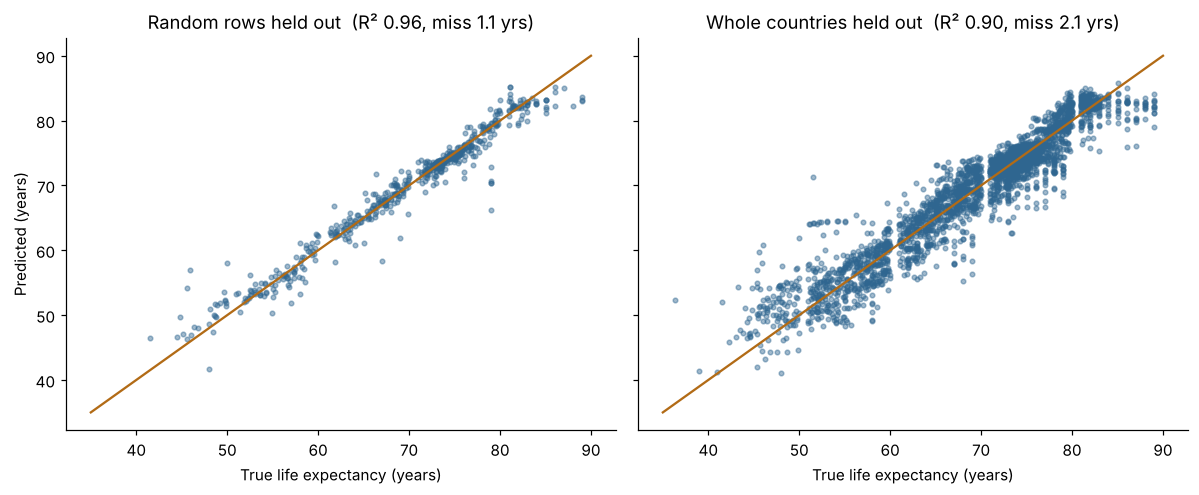

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (truth, p, title) in zip(axes, [(y_te, pred, f"Random rows held out  (R² {r2_random:.2f}, miss {mae_random:.1f} yrs)"),
                                        (y, oof, f"Whole countries held out  (R² {r2_group:.2f}, miss {mae_group:.1f} yrs)")]):
    ax.scatter(truth, p, s=9, alpha=0.45, color="#2F6690")
    ax.plot([35, 90], [35, 90], color="#B26B16", lw=1.5)
    ax.set(title=title, xlabel="True life expectancy (years)")
axes[0].set_ylabel("Predicted (years)")
plt.tight_layout(); plt.show()

**How to read it.** Each dot is one country-year. Left: the random test; right: the honest test. The orange line is "prediction equals truth".

**What it means.** On the right, the dots are visibly more scattered, and the scatter is worst at the bottom-left: countries with very low life expectancy are predicted too high. These are the countries the model has the least experience with, so when one is held out there is little to learn from. Notebook 5 names them and asks why.

**What's next and why.** Compare the live numbers against the project's published results, then move on to what drives the predictions.

## Step 5: Do the live numbers match the published ones?

**What we are looking for.** The project's build scripts save their results in `model/`; the website and documentation are generated from those files. The numbers computed in this notebook should match them.

In [5]:
meta = results("metadata")
gcv = results("diagnostics")["group_cv"]
pd.DataFrame({
    "This notebook": [round(r2_random, 3), round(mae_random, 2), round(r2_group, 3), round(mae_group, 2)],
    "Published (model/metadata.json, diagnostics.json)": [round(meta["test_r2"], 3), round(meta["test_mae"], 2), round(gcv["group"]["r2_mean"], 3), round(gcv["group"]["oof_mae"], 2)],
}, index=["R², random split", "Average miss, random split (years)", "R², unseen countries", "Average miss, unseen countries (years)"])

,This notebook,"Published (model/metadata.json, diagnostics.json)"
"R², random split",0.960,0.960
"Average miss, random split (years)",1.150,1.150
"R², unseen countries",0.901,0.901
"Average miss, unseen countries (years)",2.140,2.140


**How to read it.** The two columns should agree to the last digit (random forests use a fixed random seed, so the result is repeatable).

**What it means.** Everything on the project page can be reproduced from the code and data in the repository. The automated tests (`tests/`) check the same thing every time the code changes.

**What's next and why.** Notebook 4 opens the model up and asks which inputs it relies on most, and whether that makes sense.

## Summary

| Test | What it asks | R² | Average miss |
| --- | --- | --- | --- |
| Random 20% of rows held out | Can you fill in a missing year for a country you know? | 0.96 | 1.15 years |
| Whole countries held out (5-fold) | Can you predict a country you have never seen? | 0.90 | 2.14 years |

The second row is the project's honest headline. The first is reported alongside it to show how much an ordinary test can overstate accuracy when the same country appears many times in the data.